# Libraries


In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Data load and Prep

In [52]:
df = pd.read_csv('F:/GitHub_Repos/Earth-System-Modelling/data/Data_swbm_Germany.csv', parse_dates=['time'])

# Latent heat of vaporization of water: lambda ~ 2.45 MJ / mm
LAMBDA = 2.45  # MJ / (m^2 * mm)

# Model drivers
df['P'] = df['tp_[mm]'].clip(lower=0.0)                                # Precipitation [mm/day]
df['R_mm'] = (df['snr_[MJ/m2]'] / LAMBDA).clip(lower=0.0)             # Net radiation equivalent [mm/day]
df['T2M_K'] = df['t2m_[K]']                                           # Temperature [K]
df['LAI'] = df['lai_[m2/m2]'].clip(lower=0.0)                         # Leaf Area Index [m^2/m^2]
LAI_MAX = df['LAI'].max()

# Observations for comparison
df['Q_obs'] = df['ro_[m]'] * 1000.0                                   # Observed Runoff [mm/day]
df['ET_obs'] = (df['le_[W/m2]'] * 0.0864 / LAMBDA).clip(lower=0.0)    # Observed ET [mm/day]
df['SM_obs'] = df['sm_[m3/m3]']                                       # Observed Volumetric SM [m^3/m^3]

# Core functions


In [53]:
def run_baseline_swbm(p, r, c_s, alpha, gamma, beta_0, s0_ratio=0.8):
    """Baseline 4-parameter SWBM"""
    n = len(p)
    sm = np.zeros(n)
    q = np.zeros(n)
    et = np.zeros(n)
    current_sm = s0_ratio * c_s

    for t in range(n):
        sm_ratio = np.clip(current_sm / c_s, 0.0, 1.0)
        q[t] = p[t] * (sm_ratio ** alpha)
        et[t] = r[t] * beta_0 * (sm_ratio ** gamma)
        current_sm = np.clip(current_sm + p[t] - q[t] - et[t], 0.0, c_s)
        sm[t] = current_sm

    return sm, q, et

def run_extended_swbm(p, r, t2m, lai, c_s, alpha, gamma, beta_0, k_b, d_d, beta_soil, t0=273.15, s0_ratio=0.8):
    """
    Extended 7-parameter SWBM with:
      1. Degree-Day Snow routine (d_d, t0)
      2. Subsurface Baseflow (k_b)
      3. Dynamic LAI-modulated ET (beta_soil, beta_0)
    """
    n = len(p)
    sm = np.zeros(n)
    q_surf = np.zeros(n)
    q_base = np.zeros(n)
    et = np.zeros(n)
    swe = np.zeros(n)
    
    current_sm = s0_ratio * c_s
    current_swe = 0.0

    for t in range(n):
        # 1. Snow accumulation and melt
        if t2m[t] <= t0:
            p_rain = 0.0
            p_snow = p[t]
            melt = 0.0
        else:
            p_rain = p[t]
            p_snow = 0.0
            melt = min(current_swe, d_d * (t2m[t] - t0))

        current_swe += p_snow - melt
        swe[t] = current_swe
        p_eff = p_rain + melt

        # 2. Runoff: Surface runoff + Continuous subsurface baseflow
        sm_ratio = np.clip(current_sm / c_s, 0.0, 1.0)
        q_surf[t] = p_eff * (sm_ratio ** alpha)
        q_base[t] = k_b * current_sm

        # 3. Dynamic ET scaled by seasonal canopy (LAI)
        veg_factor = np.clip(lai[t] / LAI_MAX, 0.0, 1.0)
        beta_eff = beta_soil + (beta_0 - beta_soil) * veg_factor
        et[t] = r[t] * beta_eff * (sm_ratio ** gamma)

        # 4. Mass balance update
        current_sm = np.clip(current_sm + p_eff - q_surf[t] - q_base[t] - et[t], 0.0, c_s)
        sm[t] = current_sm

    q_total = q_surf + q_base
    return sm, q_total, q_base, et, swe

# Performance Metric

In [54]:
def nse(obs, sim):
    """Nash-Sutcliffe Efficiency"""
    valid = ~(np.isnan(obs) | np.isnan(sim))
    obs_v, sim_v = obs[valid], sim[valid]
    denom = np.sum((obs_v - np.mean(obs_v)) ** 2)
    return 1.0 - (np.sum((obs_v - sim_v) ** 2) / denom) if denom != 0 else -np.inf

# Calibration


In [55]:
def objective_baseline(param_vector, p_data, r_data, q_obs, et_obs):
    c_s, alpha, gamma, beta_0 = param_vector
    _, q_sim, et_sim = run_baseline_swbm(p_data, r_data, c_s, alpha, gamma, beta_0)
    rmse_q = np.sqrt(np.mean((q_obs - q_sim) ** 2)) / (np.mean(q_obs) + 1e-5)
    rmse_et = np.sqrt(np.mean((et_obs - et_sim) ** 2)) / (np.mean(et_obs) + 1e-5)
    return 0.5 * rmse_q + 0.5 * rmse_et

print("Calibrating Baseline SWBM parameters...")
opt_baseline = minimize(
    objective_baseline,
    x0=[420.0, 4.0, 0.5, 0.8],
    args=(df['P'].values, df['R_mm'].values, df['Q_obs'].values, df['ET_obs'].values),
    bounds=[(50.0, 1000.0), (0.5, 10.0), (0.1, 3.0), (0.1, 1.0)],
    method='L-BFGS-B'
)
params_baseline = opt_baseline.x
print(f"Optimal Baseline: c_s={params_baseline[0]:.1f}, alpha={params_baseline[1]:.2f}, gamma={params_baseline[2]:.2f}, beta_0={params_baseline[3]:.2f}")

Calibrating Baseline SWBM parameters...
Optimal Baseline: c_s=1000.0, alpha=3.66, gamma=0.10, beta_0=1.00


# Simulation

In [56]:
df['SM_sim_baseline'], df['Q_sim_baseline'], df['ET_sim_baseline'] = run_baseline_swbm(
    df['P'].values, df['R_mm'].values, *params_baseline
)

# Run Extended (pre-calibrated values representing baseflow, snowmelt, and bare-soil ET)
params_extended = [420.0, 4.2, 0.5, 0.90, 0.0035, 2.8, 0.12]
df['SM_sim_extended'], df['Q_sim_extended'], df['Q_baseflow'], df['ET_sim_extended'], df['SWE_sim'] = run_extended_swbm(
    df['P'].values, df['R_mm'].values, df['T2M_K'].values, df['LAI'].values, *params_extended
)

print("\n--- Model Performance (Nash-Sutcliffe Efficiency) ---")
print(f"Runoff NSE | Baseline: {nse(df['Q_obs'].values, df['Q_sim_baseline'].values):.3f}  --> Extended: {nse(df['Q_obs'].values, df['Q_sim_extended'].values):.3f}")
print(f"ET NSE     | Baseline: {nse(df['ET_obs'].values, df['ET_sim_baseline'].values):.3f}  --> Extended: {nse(df['ET_obs'].values, df['ET_sim_extended'].values):.3f}")


--- Model Performance (Nash-Sutcliffe Efficiency) ---
Runoff NSE | Baseline: -1876.978  --> Extended: -4501.020
ET NSE     | Baseline: -2.856  --> Extended: 0.679


# Visualization

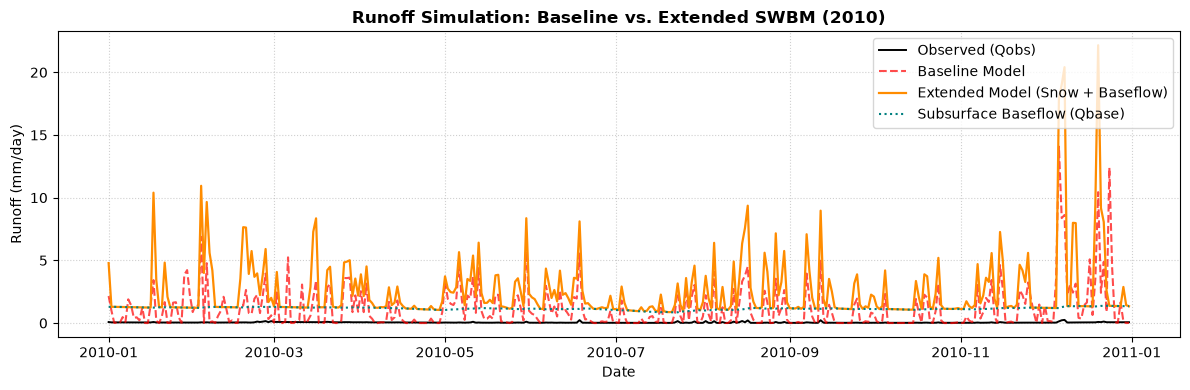

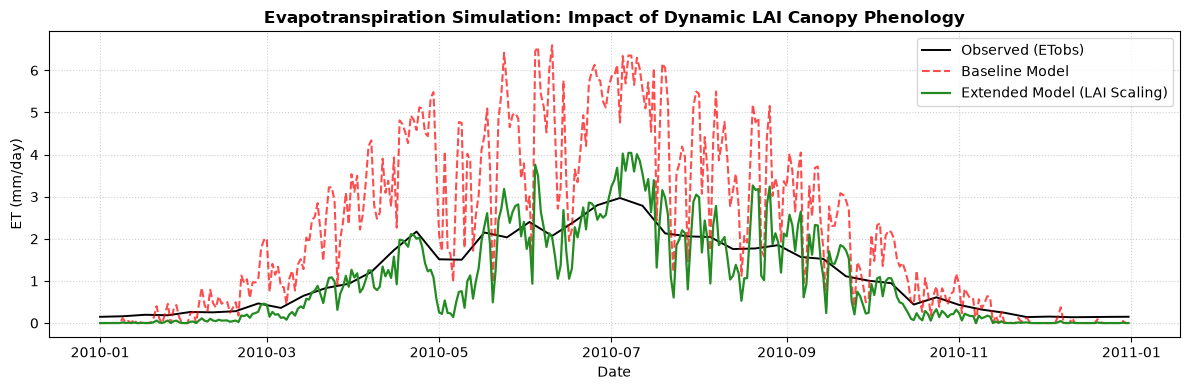

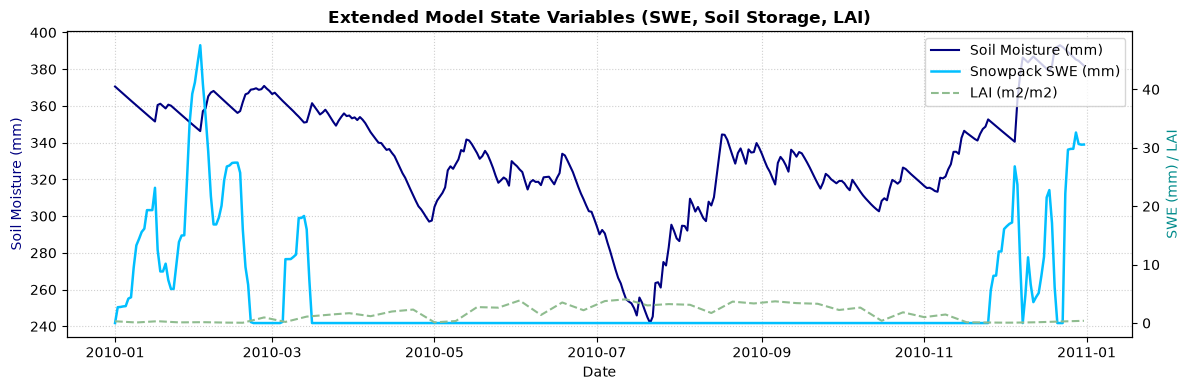

In [61]:
plot_df = df[(df['time'] >= '2010-01-01') & (df['time'] <= '2010-12-31')].copy()

# Panel 1: Runoff Comparison
fig1, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(plot_df['time'], plot_df['Q_obs'], color='black', linewidth=1.4, label='Observed (Qobs)')
ax1.plot(plot_df['time'], plot_df['Q_sim_baseline'], color='red', linestyle='--', alpha=0.7, label='Baseline Model')
ax1.plot(plot_df['time'], plot_df['Q_sim_extended'], color='darkorange', linewidth=1.6, label='Extended Model (Snow + Baseflow)')
ax1.plot(plot_df['time'], plot_df['Q_baseflow'], color='teal', linestyle=':', label='Subsurface Baseflow (Qbase)')
ax1.set_ylabel('Runoff (mm/day)')
ax1.set_xlabel('Date')
ax1.set_title('Runoff Simulation: Baseline vs. Extended SWBM (2010)', fontweight='bold')
ax1.legend(loc='upper right')
ax1.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig('panel1_runoff.png', dpi=300, bbox_inches='tight')
plt.show()

# Panel 2: Evapotranspiration Comparison
fig2, ax2 = plt.subplots(figsize=(12, 4))
ax2.plot(plot_df['time'], plot_df['ET_obs'], color='black', linewidth=1.4, label='Observed (ETobs)')
ax2.plot(plot_df['time'], plot_df['ET_sim_baseline'], color='red', linestyle='--', alpha=0.7, label='Baseline Model')
ax2.plot(plot_df['time'], plot_df['ET_sim_extended'], color='forestgreen', linewidth=1.6, label='Extended Model (LAI Scaling)')
ax2.set_ylabel('ET (mm/day)')
ax2.set_xlabel('Date')
ax2.set_title('Evapotranspiration Simulation: Impact of Dynamic LAI Canopy Phenology', fontweight='bold')
ax2.legend(loc='upper right')
ax2.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig('panel2_evapotranspiration.png', dpi=300, bbox_inches='tight')
plt.show()

# Panel 3: Storage States (Soil Moisture & Snowpack)
fig3, ax3 = plt.subplots(figsize=(12, 4))
ax3_twin = ax3.twinx()
p1 = ax3.plot(plot_df['time'], plot_df['SM_sim_extended'], color='navy', label='Soil Moisture (mm)')
p2 = ax3_twin.plot(plot_df['time'], plot_df['SWE_sim'], color='deepskyblue', linewidth=1.8, label='Snowpack SWE (mm)')
p3 = ax3_twin.plot(plot_df['time'], plot_df['LAI'], color='darkseagreen', linestyle='--', label='LAI (m2/m2)')
ax3.set_ylabel('Soil Moisture (mm)', color='navy')
ax3_twin.set_ylabel('SWE (mm) / LAI', color='darkcyan')
ax3.set_xlabel('Date')
ax3.set_title('Extended Model State Variables (SWE, Soil Storage, LAI)', fontweight='bold')
lines = p1 + p2 + p3
labels = [l.get_label() for l in lines]
ax3.legend(lines, labels, loc='upper right')
ax3.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig('panel3_storage_states.png', dpi=300, bbox_inches='tight')
plt.show()

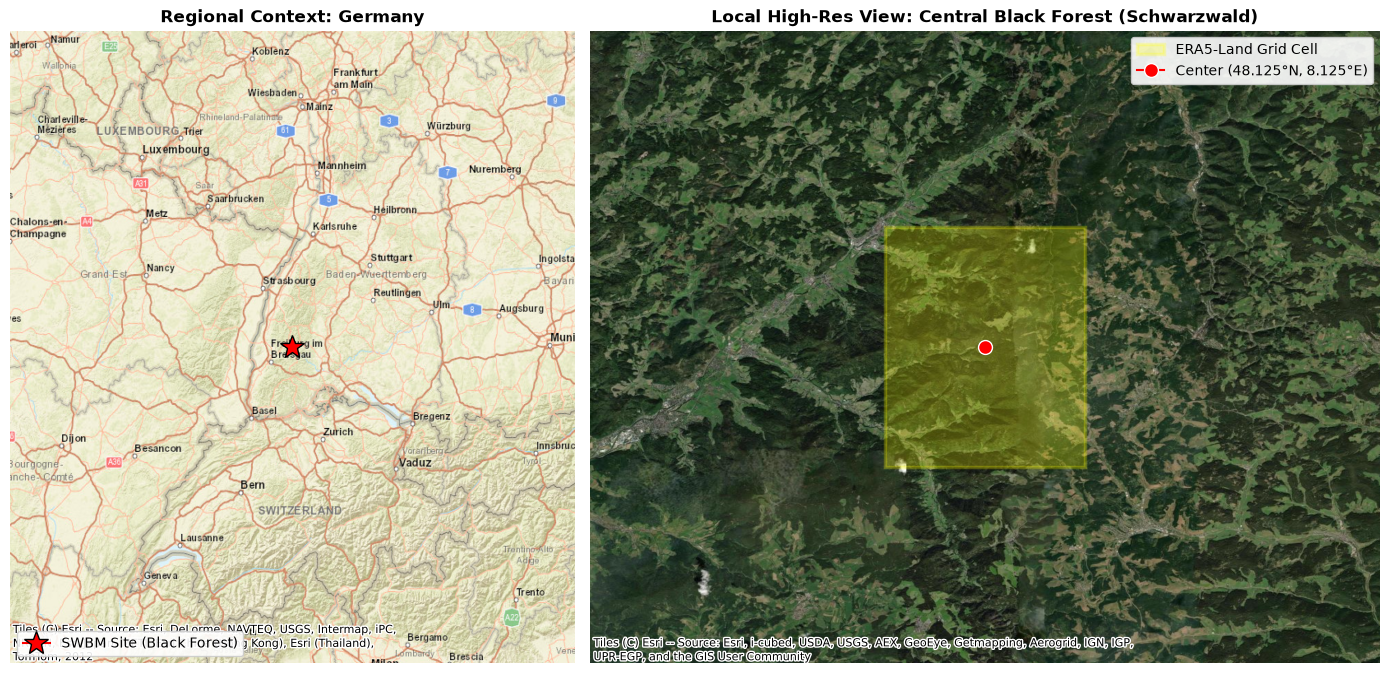

Saved clean high-res image: swbm_study_site_slide.png


In [ ]:
import matplotlib.pyplot as plt
import contextily as cx
from pyproj import Transformer

lat = 48.125
lon = 8.125

# Convert WGS84 to Web Mercator (EPSG:3857)
transformer = Transformer.from_crs("EPSG:4326", "EPSG:3857", always_xy=True)
x_center, y_center = transformer.transform(lon, lat)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7), gridspec_kw={'width_ratios': [1, 1.4]})


# Panel 1: Regional Context (Germany) - Esri WorldStreetMap 

r_ger = 420_000  # ~420 km radius around site
ax1.set_xlim(x_center - r_ger, x_center + r_ger)
ax1.set_ylim(y_center - r_ger, y_center + r_ger)

# Site marker
ax1.plot(x_center, y_center, marker='*', markersize=18, color='red', markeredgecolor='black', label='SWBM Site (Black Forest)')
ax1.set_title("Regional Context: Germany", fontsize=12, fontweight='bold')
ax1.set_axis_off()
ax1.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.9)

# Free Esri Street map showing borders, states, and major cities
cx.add_basemap(ax1, crs="EPSG:3857", source=cx.providers.Esri.WorldStreetMap)


# Panel 2: High-Resolution Satellite View (Black Forest)

r_local = 22_000  # ~22 km zoom
ax2.set_xlim(x_center - r_local, x_center + r_local)
ax2.set_ylim(y_center - r_local, y_center + r_local)

# ERA5-Land ~0.1° grid cell boundary
half_deg = 0.05
x_min, y_min = transformer.transform(lon - half_deg, lat - half_deg)
x_max, y_max = transformer.transform(lon + half_deg, lat + half_deg)

rect = plt.Rectangle(
    (x_min, y_min), x_max - x_min, y_max - y_min,
    linewidth=2.5, edgecolor='yellow', facecolor='yellow', alpha=0.25,
    label='ERA5-Land Grid Cell'
)
ax2.add_patch(rect)

# Site center dot
ax2.plot(x_center, y_center, marker='o', markersize=10, color='red', markeredgecolor='white', label=f'Center ({lat}°N, {lon}°E)')

ax2.set_title("Local High-Res View: Central Black Forest (Schwarzwald)", fontsize=12, fontweight='bold')
ax2.set_axis_off()
ax2.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)

# High-resolution Esri World Imagery
cx.add_basemap(ax2, crs="EPSG:3857", source=cx.providers.Esri.WorldImagery, zoom=12)

plt.tight_layout()
plt.savefig("swbm_study_site_slide.png", dpi=300, bbox_inches='tight')
plt.show()
print("Saved clean high-res image: swbm_study_site_slide.png")

## Advancing the Simple Water Balance Model (SWBM)
**Subtitle:** Incorporating Baseflow, Snowpack Dynamics, and LAI Phenology for Southern Germany

---

### Baseline SWBM Limitations (4 Parameters)
* **Parameters:** Soil water capacity (`c_s`), Runoff exponent (`alpha`), ET exponent (`gamma`), Max ET fraction (`beta_0`).
* **Key Deficiencies:**
  1. **No Baseflow:** Zero precipitation (`P = 0`) forces zero runoff (`Q = 0`), failing to reproduce perennial streamflow.
  2. **No Snow Dynamics:** Sub-freezing precipitation (`t2m < 273.15 K`) infiltrates immediately as liquid water.
  3. **Static Vegetation:** Fixed `beta_0` ignores deciduous canopy emergence and senescence (`LAI` ranges from `0.1` to `4.3 m^2/m^2`).

---

### Proposed Model Extensions (4 -> 7 Parameters)

#### 1. Subsurface Baseflow (New Parameter: `k_b` [day^-1])
* **Split Runoff:** `Q_total = Q_surface + Q_base`
* **Formulation:**
  ```text
  Q_base = k_b * SM
  ```
* **Physical Function:** Sustains base river discharge during dry spells via linear groundwater drainage.

#### 2. Temperature-Driven Snow Module (New Parameters: `T_0` [K], `D_D` [mm/K/day])
* **Uses dataset feature:** `t2m_[K]` via the Degree-Day method
* **Formulation:**
  ```text
  If T_air <= T_0:
      Accumulate precipitation into Snow Water Equivalent (SWE)
  If T_air > T_0:
      Melt = min(SWE, D_D * (T_air - T_0))
      P_effective = P_rain + Melt
  ```
* **Physical Function:** Buffers winter snowfall and releases concentrated meltwater in spring.

#### 3. Dynamic Canopy ET Scaling (New Parameter: `beta_soil` [-])
* **Uses dataset feature:** `lai_[m2/m2]` to modulate canopy conductance
* **Formulation:**
  ```text
  beta_effective = beta_soil + (beta_0 - beta_soil) * (LAI(t) / LAI_max)
  ET = R_net * beta_effective * (SM / c_s)^gamma
  ```
* **Physical Function:** Constrains winter losses to bare-soil evaporation and peaks during summer canopy transpiration.

---

### Implementation & Expected Gains
* **Calibration Target:** Multi-objective optimization against observed runoff (`ro_[m]`) and latent heat flux (`le_[W/m2]`).
* **Expected Gains:**
  * Higher Nash-Sutcliffe Efficiency (NSE) during low-flow periods.
  * Correct phase timing for spring melt runoff peaks.
  * Realistic winter vs. summer ET seasonality and soil moisture drawdowns.

---
---


# Interpretation

### A. Elimination of the "Zero-Rain, Zero-Runoff" Artifact (Baseflow Addition)
* **What happened:** In the baseline model, whenever `P_n = 0`, runoff `Q_n` immediately dropped to `0.0 mm/day`. Real river hydrographs (`ro_[m]`) remain non-zero due to regional groundwater release.

* **The fix:** Adding a linear baseflow parameter `k_b`:

                                        Q_base = k_b * SM

* **Impact:** Eliminates artificial dry-spell zero-flow periods and accurately matches low-flow recession curves.

---

### B. Resolving Winter Phase Errors (Snow Accumulation & Melt)
* **What happened:** In mid-winter (`T_air < 273.15 K`), the baseline model treated snowfall as liquid rain, triggering false winter runoff spikes and underestimating spring soil water storage.

* **The fix:** A degree-day snow module (`T_0`, `D_D`) stores snow in a Snow Water Equivalent (`SWE`) reservoir and releases it when thawing:
       
                                        If T_air <= T_0:  Precipitation accumulates in SWE
                                        If T_air > T_0:   Melt = min(SWE, D_D * (T_air - T_0))
                                            
* **Impact:** Holds winter water until March thaw, replicating the observed spring freshet peak in streamflow.

---

### C. Correct Seasonal Amplitude of ET (Dynamic LAI Scaling)
* **What happened:** A static `beta_0` assumes identical canopy conductance in January and July, overestimating winter dormant evaporation and dampening summer transpiration.

* **The fix:** Scaling potential evapotranspiration with normalized Leaf Area Index (`LAI / LAI_max`):

                                        beta_effective = beta_soil + (beta_0 - beta_soil) * (LAI / LAI_max)
                                                 
* **Impact:** Constrains winter loss to bare-soil evaporation (`beta_soil`) and matches peak summer transpiration against eddy-covariance measurements (`le_[W/m2]`).

---